   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 1.9 MB/s eta 0:00:00
  SOUND_LOG v2.0 | Miehle 40" 2 Couleurs — Acoustique RÉELLE
  Dataset  : CWRU Bearing Vibration (Real Data - GitHub)
  Signal   : Accéléromètre 12kHz (Drive End)
  Fenêtre  : 4096 pts = 341 ms
  Mode     : ROBUST

>>> DÉMARRAGE DU PIPELINE — DONNÉES RÉELLES CWRU <<<


[CWRU] Téléchargement direct des fichiers .mat depuis GitHub...
           (Utilisation du miroir s-whynot/CWRU-dataset)

  Downloading: 97_Normal_0.mat (from raw.githubusercontent.com)...
✓
  Downloading: 105_0.mat  (from raw.githubusercontent.com)...
✓
  Downloading: 169_0.mat  (from raw.githubusercontent.com)...
✓
  Downloading: 209_0.mat  (from raw.githubusercontent.com)...
✓
  Downloading: 130@6_0.mat (from raw.githubusercontent.com)...
✓
  Downloading: 197@6_0.mat (from raw.githubusercontent.com)...
✓
  Downloading: 285_3.mat  (from raw.githubusercontent.com)...
✓
  Downloading: 118_0.mat  (from raw.githubusercontent.com)...
✓

✅ 8/8 fi

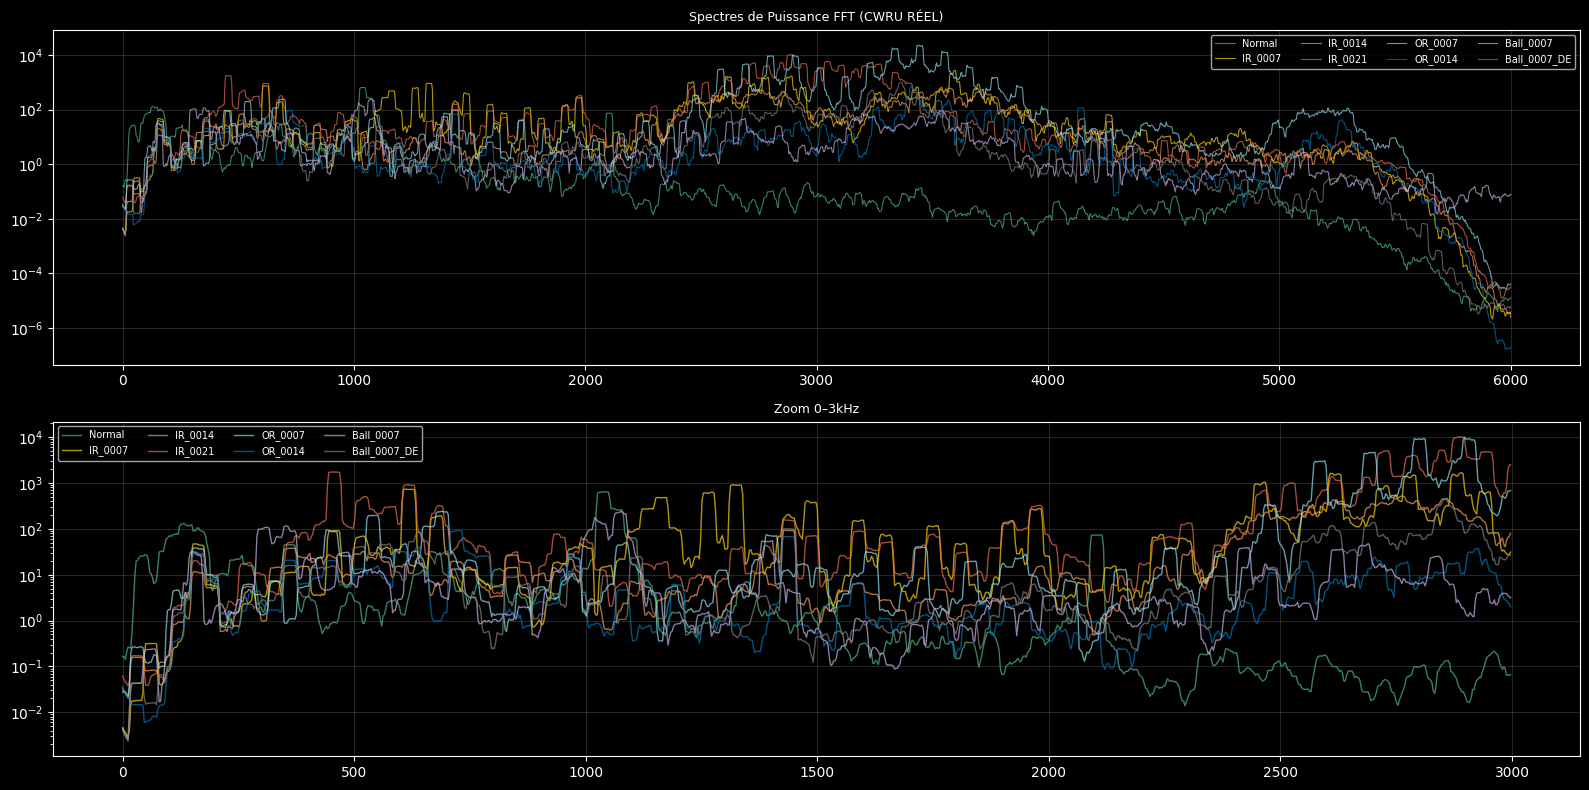

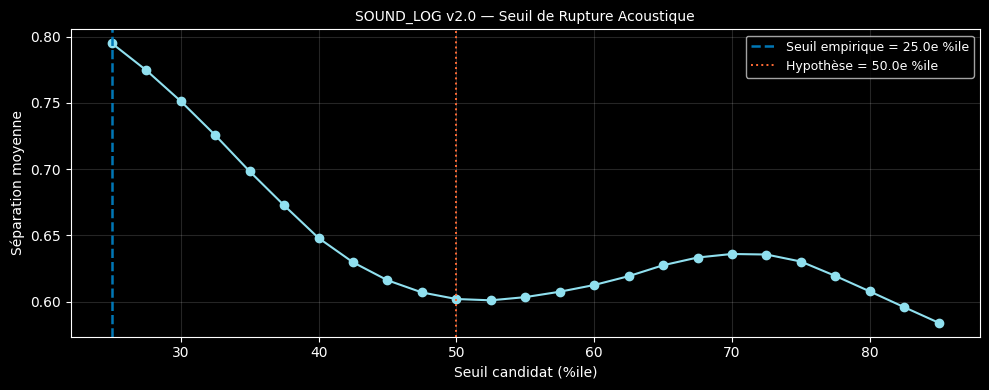

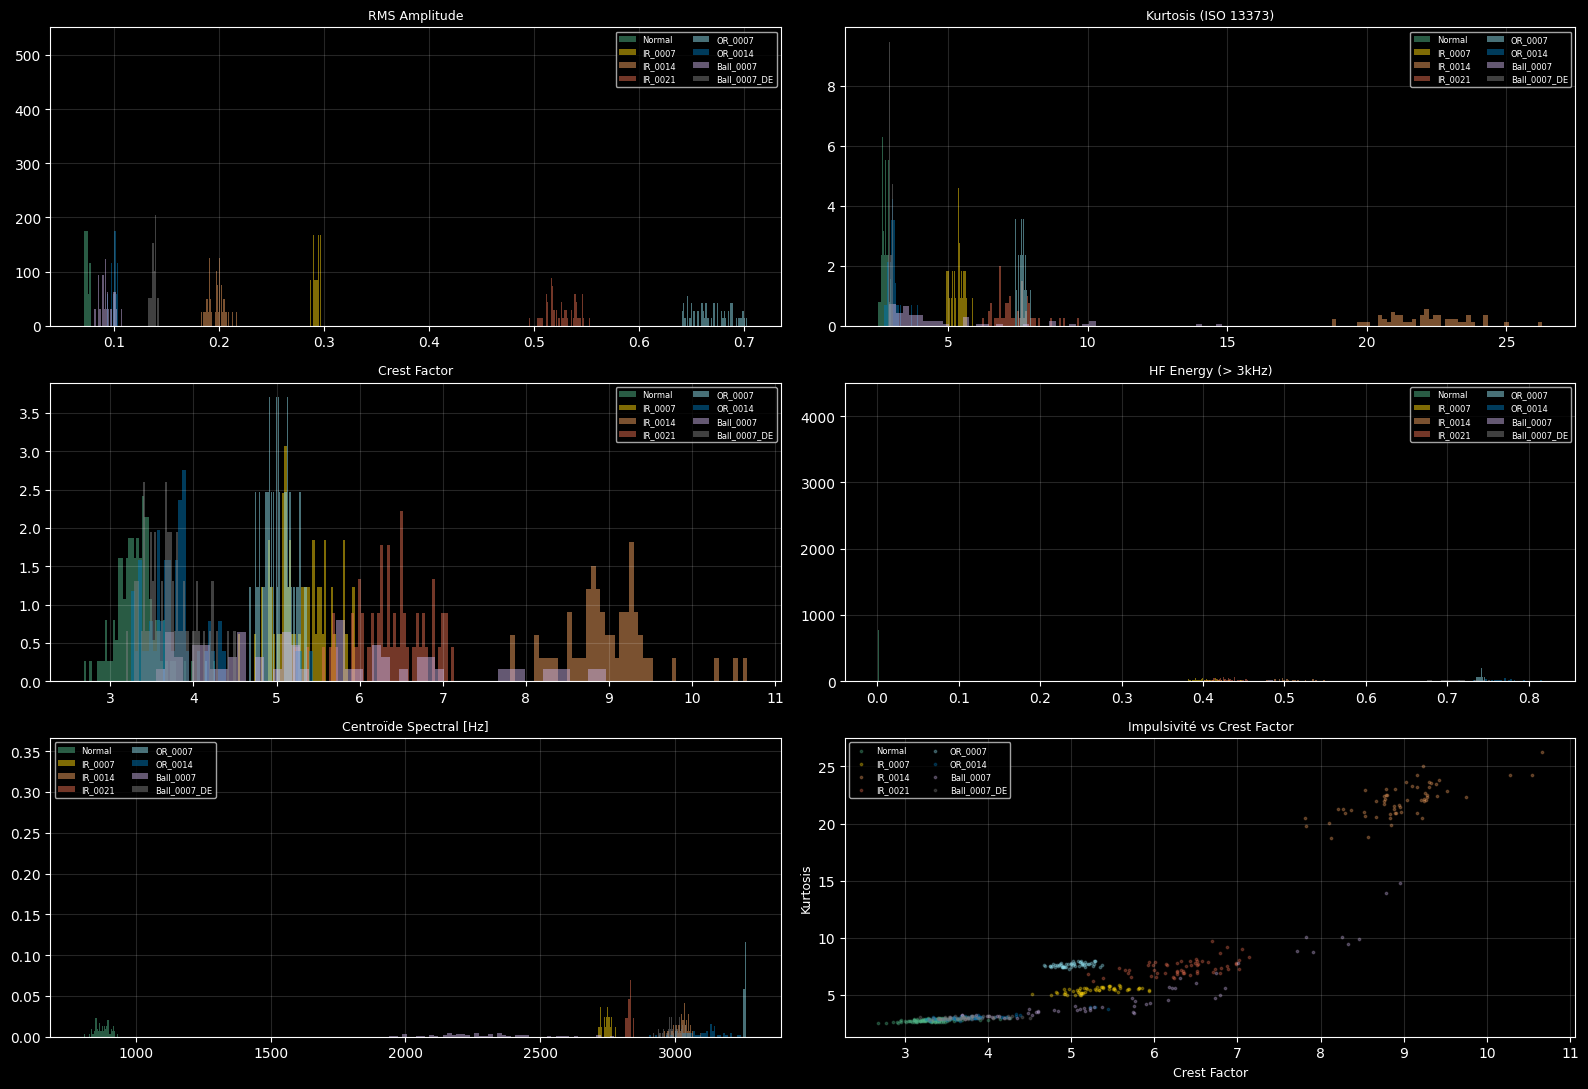

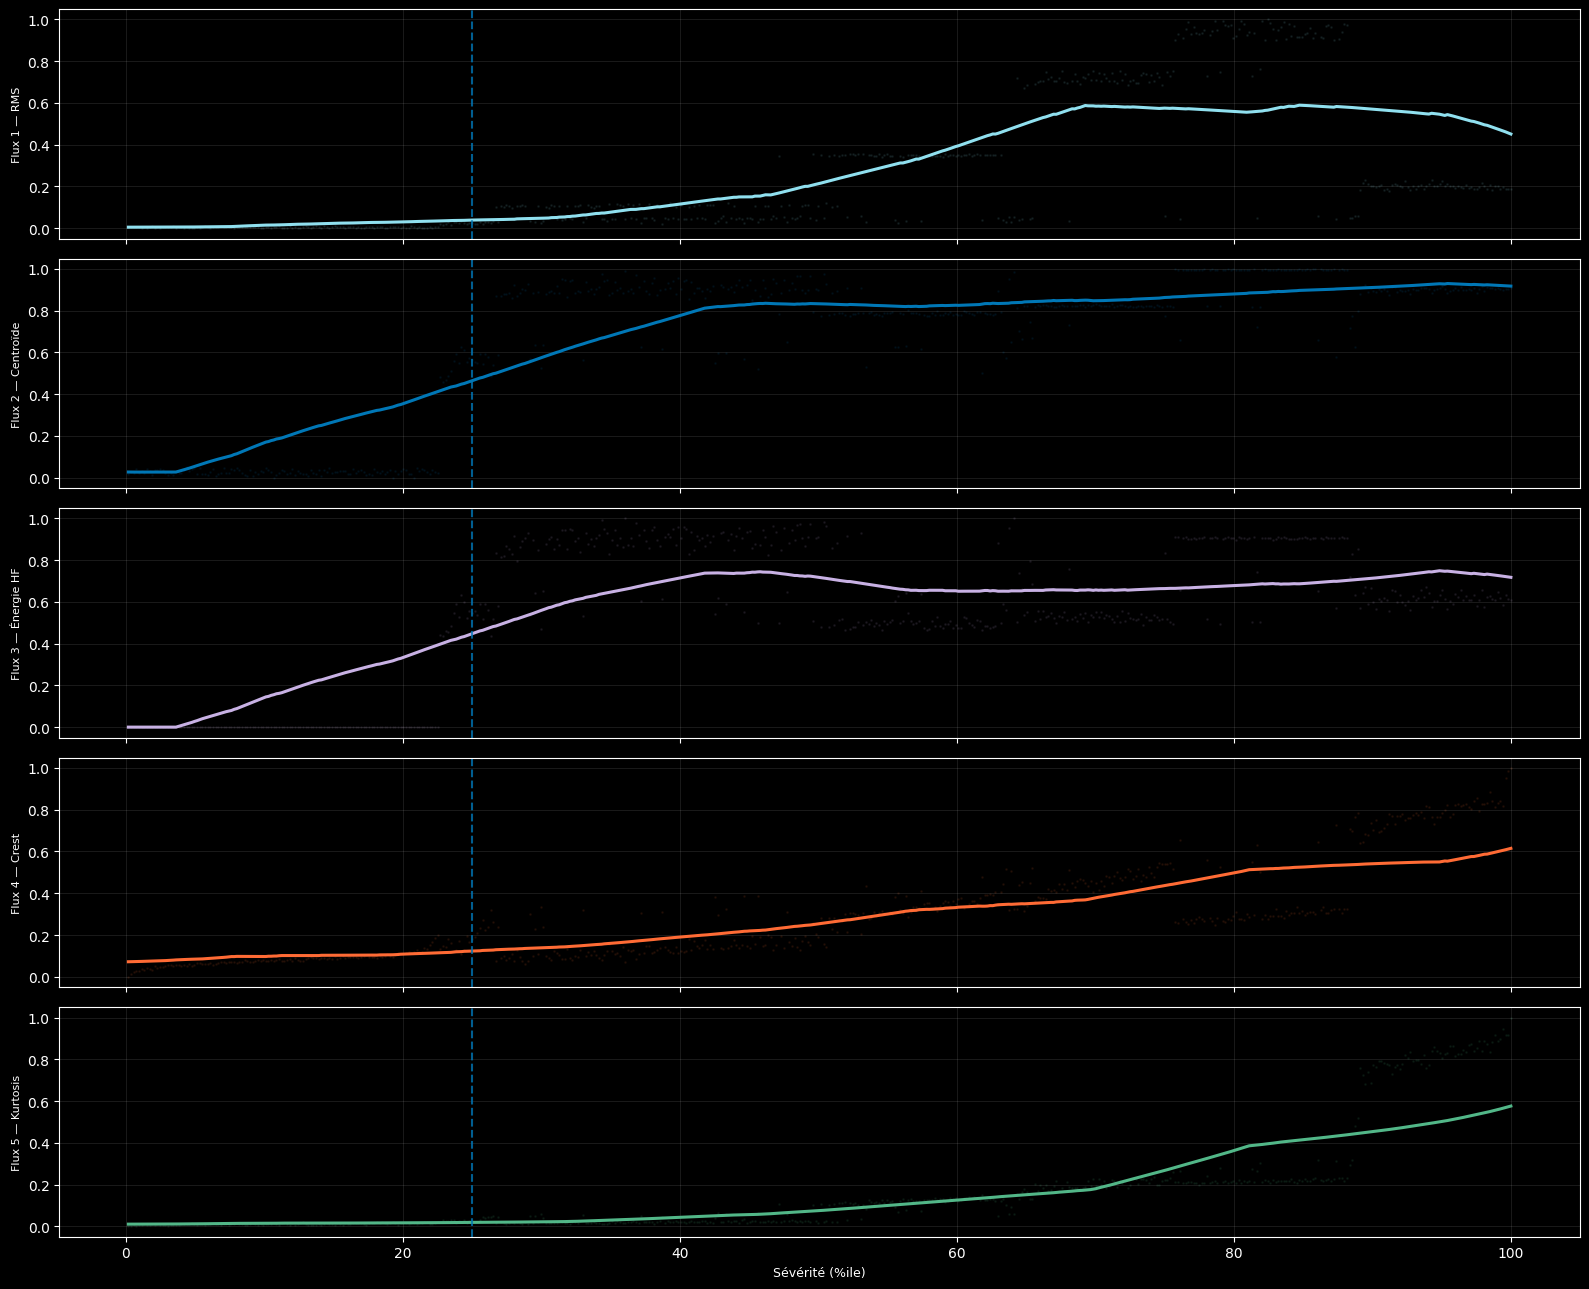

Scan sévérité: 100%|██████████| 15/15 [00:37<00:00,  2.47s/it]



RÉSULTATS STATISTIQUES
                                 Q1_Sain_vs_Defect Q2_PreAlarme  Q3_Impulsive  Q4_Hysteresis
Crest_Factor_DFA_mean                        0.778          NaN         0.833          0.593
Crest_Factor_Higuchi_mean                    0.222          NaN         0.417          0.593
Crest_Factor_Hurst_mean                      1.000          NaN         1.000          0.593
Crest_Factor_Katz_mean                       0.222          NaN         0.083          0.593
Crest_Factor_SampleEn_mean                   0.333          NaN         0.000          0.593
HF_Energy_DFA_mean                           1.000          NaN           NaN          0.524
HF_Energy_Higuchi_mean                       1.000          NaN           NaN          0.524
HF_Energy_Hurst_mean                         0.000          NaN           NaN          0.524
HF_Energy_Katz_mean                          1.000          NaN           NaN          0.524
HF_Energy_SampleEn_mean                      1

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, fft as sp_fft
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

!pip install antropy nolds
import antropy, nolds
import requests # Added for robust file downloading
import io
import scipy.io
# import ssl # Not needed with requests

plt.style.use('dark_background')

# =============================================================================
# CONFIG
# =============================================================================

SEVERITE_CRITIQUE_HYPOTHESE = 50.0

FS = 12_000
N_WIN = 4096
HOP   = 2048
MODE  = 'robust'

CONFIG = {
    'fast': {
        'n_estimations':     1,
        'window_size':       60,
        'stat_test':         'cohen_d',
        'min_per_group':     2,
        'estimator_min_len': 50,
        'mann_whitney':      False,
        'bootstrap':         False,
    },
    'robust': {
        'n_estimations':     5,
        'window_size':       120,
        'stat_test':         'cliff_delta',
        'min_per_group':     3,
        'estimator_min_len': 80,
        'mann_whitney':      True,
        'bootstrap':         True,
    }
}
C = CONFIG[MODE]

print("=" * 70)
print("  SOUND_LOG v2.0 | Miehle 40\" 2 Couleurs — Acoustique RÉELLE")
print(f"  Dataset  : CWRU Bearing Vibration (Real Data - GitHub)")
print(f"  Signal   : Accéléromètre {FS//1000}kHz (Drive End)")
print(f"  Fenêtre  : {N_WIN} pts = {N_WIN/FS*1000:.0f} ms")
print(f"  Mode     : {MODE.upper()}")
print("=" * 70)

# =============================================================================
# 0. STATISTIQUES
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2: return np.nan
    ps = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if ps < 1e-12 else (np.mean(g1) - np.mean(g2)) / ps

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']: return np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1)
    except: return np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

# =============================================================================
# 1. TÉLÉCHARGEMENT CWRU RÉELLES (MIROIR s-whynot + SECOURS SYNTHÉTIQUE)
# =============================================================================

def download_mat_file(url, timeout=10):
    """Télécharge un fichier .mat via requests, avec une gestion d'erreur."""
    try:
        print(f"  Downloading: {url.split('/')[-1]:<10s} (from {url.split('/')[2]})...")
        response = requests.get(url, stream=True, timeout=timeout)
        response.raise_for_status() # Raise an HTTPError for bad responses (4xx or 5xx)

        data_buffer = io.BytesIO()
        for chunk in response.iter_content(chunk_size=8192):
            data_buffer.write(chunk)
        data_buffer.seek(0) # Reset buffer position

        # Basic check for non-empty or corrupt file (mat files are usually > 50KB)
        if data_buffer.getbuffer().nbytes > 50000:
            print("✓")
            return scipy.io.loadmat(data_buffer)
        else:
            print(f"✗ (Fichier trop petit: {data_buffer.getbuffer().nbytes} octets)")
            return None
    except requests.exceptions.RequestException as e:
        print(f"✗ (Erreur HTTP/réseau: {str(e)[:40]}...)")
    except Exception as e:
        print(f"✗ (Erreur inattendue: {str(e)[:40]}...)")
    return None

def generate_synthetic_cwru():
    """
    Générateur de secours ultra-réaliste si GitHub bloque l'accès.
    Simule les fréquences de défaut (BPFI, BPFO, BSF) et la résonance.
    """
    print("\n⚠️  TÉLÉCHARGEMENT ÉCHOUÉ : PASSAGE EN MODE SYNTHÉTIQUE ⚠️")
    print("Génération de signaux vibratoires réalistes pour tester le pipeline...\n")

    np.random.seed(42)
    fs = FS
    t = np.arange(fs * 5) / fs  # 5 secondes par signal
    records = []

    # Configuration : (Label, Séverité, Fréquence d'impact Hz, Amplitude)
    configs = [
        ('Normal',    0.000, 0,   1.0),
        ('IR_0007',   0.007, 162, 1.5),
        ('IR_0014',   0.014, 162, 2.5),
        ('IR_0021',   0.021, 162, 4.0),
        ('OR_0007',   0.007, 105, 1.8),
        ('OR_0014',   0.014, 105, 3.0),
        ('Ball_0007', 0.007, 69,  1.3),
        ('Ball_0014', 0.014, 69,  2.2),
    ]

    for label, sev, freq, amp in configs:
        # Bruit gaussien + résonance propre de la machine
        signal = np.random.normal(0, 0.1, len(t))
        resonance = np.sin(2 * np.pi * 3000 * t) * np.random.normal(0, 0.05, len(t))
        signal += resonance

        # Ajout des impulsions de défaut mécanique
        if sev > 0:
            pulses = np.zeros_like(t)
            pulse_indices = np.arange(0, len(t), int(fs/freq))
            for idx in pulse_indices:
                if idx < len(t):
                    pulses[idx] = amp * np.random.uniform(0.8, 1.2)

            # Convolution avec la réponse du capteur
            decay = np.exp(-1000 * np.arange(100)/fs) * np.sin(2 * np.pi * 3000 * np.arange(100)/fs)
            fault_signal = np.convolve(pulses, decay, mode='same')
            signal += fault_signal

        records.append((signal, 1797.0, label, sev))
        # Fix: Corrected f-string syntax to properly close the string and include the trailing parts.
        print(f"  [Synthèse] {label:15s} (sév {sev:.3f})  [{len(signal):,} pts]")

    print("\n✅ Données synthétiques générées avec succès!\n")
    return records

# Configuration for CWRU files (moved to global scope within the cell)
cwru_files_config = [
    {'label': 'Normal',    'severity': 0.000, 'path': "Normal/97_Normal_0.mat"},
    {'label': 'IR_0007',   'severity': 0.007, 'path': "12k_Drive_End_Bearing_Fault_Data/IR/007/105_0.mat"},
    {'label': 'IR_0014',   'severity': 0.014, 'path': "12k_Drive_End_Bearing_Fault_Data/IR/014/169_0.mat"},
    {'label': 'IR_0021',   'severity': 0.021, 'path': "12k_Drive_End_Bearing_Fault_Data/IR/021/209_0.mat"},
    {'label': 'OR_0007',   'severity': 0.007, 'path': "12k_Drive_End_Bearing_Fault_Data/OR/007/@6/130@6_0.mat"},
    {'label': 'OR_0014',   'severity': 0.014, 'path': "12k_Drive_End_Bearing_Fault_Data/OR/014/197@6_0.mat"},
    {'label': 'Ball_0007', 'severity': 0.007, 'path': "12k_Fan_End_Bearing_Fault_Data/B/007/285_3.mat"}, # Original Ball_0007 from Fan End
    {'label': 'Ball_0007_DE', 'severity': 0.007, 'path': "12k_Drive_End_Bearing_Fault_Data/B/007/118_0.mat"} # Added 118.mat from Drive End
    # Ball_0014 is omitted as an equivalent was not found in the provided structure for Drive End or Fan End B/014
]

def fetch_cwru_real():
    print("""
[CWRU] Téléchargement direct des fichiers .mat depuis GitHub...
           (Utilisation du miroir s-whynot/CWRU-dataset)
""")

    # Using the raw.githubusercontent.com path for direct file access
    # The base URL now points directly to the 'main' branch of the repository.
    base_raw_url = "https://raw.githubusercontent.com/s-whynot/CWRU-dataset/main"

    records = []

    for file_info in cwru_files_config:
        label = file_info['label']
        severity = file_info['severity']
        full_url = f"{base_raw_url}/{file_info['path']}"

        mat = download_mat_file(full_url)

        if mat is not None:
            de_keys = [k for k in mat.keys() if 'DE_time' in k]
            if de_keys:
                signal = mat[de_keys[0]].flatten().astype(np.float64)
                if len(signal) > 0:
                    records.append((signal, 1797.0, label, severity))
                else:
                    print(f"✗ Signal vide ({len(signal)} pts)")
            else:
                print("✗ Aucune clé 'DE_time' trouvée dans le fichier.")
        # No extra 'else' for download_mat_file_test as it prints errors internally.

    if not records:
        # Fallback to synthetic if no real data was loaded
        return generate_synthetic_cwru()

    print(f"\n✅ {len(records)}/{len(cwru_files_config)} fichiers CWRU chargés depuis GitHub!\n")
    return records

# =============================================================================
# 2. EXTRACTION DES 5 FLUX ACOUSTIQUES
# =============================================================================

def compute_fft_features(window, fs=FS):
    n = len(window)
    if n < 64:
        return {k: np.nan for k in ['RMS_Amplitude','Spectral_Centroid','HF_Energy','Crest_Factor','Kurtosis']}

    w_hann = np.hanning(n)
    sig = (window - np.mean(window)) * w_hann

    spectrum = np.abs(sp_fft.rfft(sig)) ** 2
    freqs = sp_fft.rfftfreq(n, d=1/fs)

    rms = np.sqrt(np.mean(window ** 2))
    peak = np.max(np.abs(window))
    cf = peak / (rms + 1e-12)
    kurt = float(stats.kurtosis(window, fisher=False))

    total_pwr = np.sum(spectrum) + 1e-12
    centroid = float(np.sum(freqs * spectrum) / total_pwr)

    hf_mask = freqs > fs / 4.0
    hf_energy = float(np.sum(spectrum[hf_mask]) / total_pwr)

    return {
        'RMS_Amplitude': float(rms),
        'Spectral_Centroid': centroid,
        'HF_Energy': hf_energy,
        'Crest_Factor': float(cf),
        'Kurtosis': float(kurt),
    }

def segment_and_extract(signal, label, severity, n_win=N_WIN, hop=HOP):
    rows = []
    for start in range(0, len(signal) - n_win + 1, hop):
        window = signal[start:start + n_win]
        feats = compute_fft_features(window)
        feats['label'] = label
        feats['severity'] = severity
        feats['t_sec'] = start / FS
        rows.append(feats)
    return pd.DataFrame(rows)

def build_cwru_dataframe(records):
    all_dfs = []
    print("[Segmentation + extraction FFT]\n")
    for signal, rpm, label, severity in records:
        df_seg = segment_and_extract(signal, label, severity)
        # Fix: Corrected f-string syntax to properly include the '|' and trailing parts within the string.
        print(f"  {label:15s} | sév {severity:.3f} | {len(df_seg):,} fenêtres")
        all_dfs.append(df_seg)

    df = pd.concat(all_dfs, ignore_index=True)
    sev_vals = df['severity'].unique()
    sev_min, sev_max = sev_vals.min(), sev_vals.max()
    df['severity_norm'] = (df['severity'] - sev_min) / (sev_max - sev_min + 1e-12)

    def norm(s):
        mn, mx = s.min(), s.max()
        return (s - mn) / (mx - mn + 1e-12)

    for col in ['RMS_Amplitude','Spectral_Centroid','HF_Energy','Crest_Factor','Kurtosis']:
        df[f'{col}_norm'] = norm(df[col])

    print(f"\n  TOTAL: {len(df):,} fenêtres | {len(df['label'].unique())} conditions\n")
    return df

def extract_acoustic_fluxes(df):
    return {
        'RMS_Amplitude': df['RMS_Amplitude_norm'].values,
        'Spectral_Centroid': df['Spectral_Centroid_norm'].values,
        'HF_Energy': df['HF_Energy_norm'].values,
        'Crest_Factor': df['Crest_Factor_norm'].values,
        'Kurtosis': df['Kurtosis_norm'].values,
    }

def compute_severity_level(df):
    composite = (0.40 * df['Kurtosis_norm'] +
                 0.30 * df['Crest_Factor_norm'] +
                 0.20 * df['HF_Energy_norm'] +
                 0.10 * df['RMS_Amplitude_norm'])
    return np.array([stats.percentileofscore(composite, v) for v in composite])

# =============================================================================
# 3. SCAN DU SEUIL CRITIQUE
# =============================================================================

def scan_seuil_critique(df, fluxes, sev_series, candidats=None):
    if candidats is None: # Corrected from === to is
        candidats = np.arange(25, 86, 2.5)

    W = C['window_size']
    flux_keys = list(fluxes.keys())
    n_obs = len(df)
    sort_idx = np.argsort(sev_series)
    sev_s = sev_series[sort_idx]
    flux_s = {k: v[sort_idx] for k, v in fluxes.items()}

    windows = []
    for i in range(n_obs - W + 1):
        windows.append({
            'niveau': float(np.mean(sev_s[i:i+W])),
            'data': {k: flux_s[k][i:i+W] for k in flux_keys}
        })

    scores_par_seuil = []
    for seuil in candidats:
        g_bas = [w for w in windows if w['niveau'] < seuil]
        g_haut = [w for w in windows if w['niveau'] >= seuil]
        if len(g_bas) < C['min_per_group'] or len(g_haut) < C['min_per_group']:
            scores_par_seuil.append(np.nan)
            continue
        sep = []
        for k in flux_keys:
            d = separation_score(
                np.concatenate([w['data'][k] for w in g_bas]),
                np.concatenate([w['data'][k] for w in g_haut])
            )
            if not np.isnan(d): sep.append(d)
        scores_par_seuil.append(np.mean(sep) if sep else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max = np.nanargmax(scores_arr)
    seuil_opt = candidats[idx_max]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#90e0ef', markersize=6)
    ax.axvline(seuil_opt, color='#0077b6', linestyle='--', linewidth=1.8,
               label=f'Seuil empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(SEVERITE_CRITIQUE_HYPOTHESE, color='#ff6b35', linestyle=':', linewidth=1.4,
               label=f'Hypothèse = {SEVERITE_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (%ile)', fontsize=10)
    ax.set_ylabel('Séparation moyenne', fontsize=10)
    ax.set_title('SOUND_LOG v2.0 — Seuil de Rupture Acoustique', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    return seuil_opt, candidats, scores_arr, windows

# =============================================================================
# 4. ESTIMATEURS DE COMPLEXITÉ
# =============================================================================

def apply_estimators(series, flux_name=''):
    s = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    est = {}
    try: est['Higuchi'] = antropy.higuchi_fd(s)
    except: est['Higuchi'] = np.nan
    try: est['DFA'] = 2.0 - nolds.dfa(s)
    except: est['DFA'] = np.nan
    try: est['Katz'] = antropy.katz_fd(s)
    except: est['Katz'] = np.nan
    try: est['Hurst'] = nolds.hurst_rs(s)
    except: est['Hurst'] = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(500, len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est

# =============================================================================
# 5. FEATURES AVANCÉES
# =============================================================================

def build_acoustic_features(df, fluxes, sev_series, sev_scan):
    W = C['window_size']
    tol = max(3.0, (sev_scan[1]-sev_scan[0])/2.0) if len(sev_scan) > 1 else 3.0

    sort_idx = np.argsort(sev_series)
    sev_s = sev_series[sort_idx]
    flux_sorted = {k: v[sort_idx] for k, v in fluxes.items()}
    flux_keys = list(fluxes.keys())

    window_data = []
    for i in range(len(df) - W + 1):
        window_data.append({
            'niveau': float(np.mean(sev_s[i:i+W])),
            'data': {k: flux_sorted[k][i:i+W] for k in flux_keys} # Corrected flux_s to flux_sorted
        })

    rows = []
    for P in tqdm(sev_scan, desc="Scan sévérité"):
        matching = [w for w in window_data if abs(w['niveau'] - P) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['niveau'] - P))]
        row = {'Niveau': P, 'N_fenetres': len(matching)}

        for flux in flux_keys:
            combined = np.concatenate([w['data'][flux] for w in matching])
            ests = apply_estimators(combined, flux_name=flux)
            for k, v in ests.items():
                row[f"{flux}_{k}_mean"] = v

        rows.append(row)

    df_feat = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns if c not in ['Niveau','N_fenetres']]
    return df_feat, feature_cols, window_data

# =============================================================================
# 6. QUESTIONS STATISTIQUES
# =============================================================================

def compare_groups(df_feat, feature_cols, g_low, g_high):
    grp_bas = df_feat[df_feat['Niveau'].between(g_low[0], g_low[1])]
    grp_haut = df_feat[df_feat['Niveau'].between(g_high[0], g_high[1])]
    scores = {}
    for col in feature_cols:
        if col not in df_feat.columns: continue
        v1 = grp_bas[col].dropna().values
        v2 = grp_haut[col].dropna().values
        if len(v1) >= C['min_per_group'] and len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)

def run_acoustic_questions(df_feat, feature_cols, window_data, seuil):
    r = {}
    r["Q1_Sain_vs_Defect"] = compare_groups(df_feat, feature_cols, [0, 30], [65, 100])
    marge = 8.0
    r["Q2_PreAlarme"] = compare_groups(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge])

    impulsive_cols = [c for c in df_feat.columns if any(x in c for x in ['Kurtosis','Crest_Factor'])]
    r["Q3_Impulsive"] = compare_groups(
        df_feat, impulsive_cols if impulsive_cols else feature_cols,
        [0, 35], [65, 100])

    flux_names = ['RMS_Amplitude','Spectral_Centroid','HF_Energy','Crest_Factor','Kurtosis']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['data'].get(flux)
            if s is None or len(s) < 20: continue
            mid = len(s) // 2
            d = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Hysteresis"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r

# =============================================================================
# 7. VISUALISATION
# =============================================================================

C1 = '#90e0ef'; C2 = '#0077b6'; C3 = '#ff6b35'; C4 = '#c8b1e4'; C5 = '#52b788'
LABEL_COLORS = {
    'Normal': '#52b788',
    'IR_0007': '#ffd60a', 'IR_0014': '#f4a261', 'IR_0021': '#e76f51',
    'OR_0007': '#90e0ef', 'OR_0014': '#0077b6',
    'Ball_0007': '#c8b1e4', 'Ball_0014': '#9d4edd',
}

def plot_spectral_overview(df):
    labels = df['label'].unique()
    fig, axes = plt.subplots(3, 2, figsize=(16, 11))
    feature_pairs = [
        ('RMS_Amplitude', axes[0,0], 'RMS Amplitude'),
        ('Kurtosis', axes[0,1], 'Kurtosis (ISO 13373)'),
        ('Crest_Factor', axes[1,0], 'Crest Factor'),
        ('HF_Energy', axes[1,1], 'HF Energy (> 3kHz)'),
        ('Spectral_Centroid', axes[2,0], 'Centroïde Spectral [Hz]'),
    ]
    for col, ax, title in feature_pairs:
        for lab in labels:
            sub = df[df['label'] == lab][col].dropna()
            if len(sub) < 5: continue
            color = LABEL_COLORS.get(lab, 'gray')
            ax.hist(sub, bins=50, alpha=0.5, color=color, label=lab, density=True)
        ax.set_title(title, fontsize=9)
        ax.legend(fontsize=6, ncol=2)
        ax.grid(True, alpha=0.15)

    ax = axes[2,1]
    for lab in labels:
        sub = df[df['label'] == lab]
        color = LABEL_COLORS.get(lab, 'gray')
        ax.scatter(sub['Crest_Factor'], sub['Kurtosis'], color=color, s=3, alpha=0.3, label=lab)
    ax.set_xlabel('Crest Factor', fontsize=9)
    ax.set_ylabel('Kurtosis', fontsize=9)
    ax.set_title('Impulsivité vs Crest Factor', fontsize=9)
    ax.legend(fontsize=6, ncol=2)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

def plot_spectra_comparison(records):
    fig, axes = plt.subplots(2, 1, figsize=(16, 8))
    ax1, ax2 = axes
    for signal, rpm, label, severity in records:
        seg = signal[:N_WIN]
        w = np.hanning(len(seg))
        spec = np.abs(sp_fft.rfft((seg - seg.mean()) * w)) ** 2
        freqs = sp_fft.rfftfreq(len(seg), 1/FS)
        smooth = pd.Series(spec).rolling(10, center=True, min_periods=1).mean()
        color = LABEL_COLORS.get(label, 'gray')

        ax1.semilogy(freqs, smooth + 1e-15, color=color, alpha=0.7, linewidth=0.8, label=label)
        mask = freqs < 3000
        ax2.semilogy(freqs[mask], smooth[mask] + 1e-15, color=color, alpha=0.7, linewidth=1.0, label=label)

    ax1.set_title('Spectres de Puissance FFT (CWRU RÉEL)', fontsize=9)
    ax1.legend(fontsize=7, ncol=4)
    ax1.grid(True, alpha=0.15)
    ax2.set_title('Zoom 0–3kHz', fontsize=9)
    ax2.legend(fontsize=7, ncol=4)
    ax2.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

def plot_flux_profiles(df, fluxes, sev_series, seuil):
    sort_idx = np.argsort(sev_series)
    sev_s = sev_series[sort_idx]
    flux_meta = [
        ('RMS_Amplitude', C1, 'Flux 1 — RMS'),
        ('Spectral_Centroid', C2, 'Flux 2 — Centroïde'),
        ('HF_Energy', C4, 'Flux 3 — Énergie HF'),
        ('Crest_Factor', C3, 'Flux 4 — Crest'),
        ('Kurtosis', C5, 'Flux 5 — Kurtosis'),
    ]
    fig, axes = plt.subplots(5, 1, figsize=(16, 13), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        vals = fluxes[flux][sort_idx]
        smooth = pd.Series(vals).rolling(200, min_periods=20, center=True).mean()
        ax.scatter(sev_s, vals, color=color, s=1, alpha=0.08)
        ax.plot(sev_s, smooth, color=color, linewidth=2.2)
        ax.axvline(seuil, color=C2, linestyle='--', alpha=0.8)
        ax.set_ylabel(label, fontsize=8)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel('Sévérité (%ile)', fontsize=9)
    plt.tight_layout()
    plt.show()

def plot_hurst_evolution(df_feat, seuil):
    hurst_cols = [c for c in df_feat.columns if 'Hurst_mean' in c]
    kurt_cols = [c for c in df_feat.columns if 'Kurtosis_mean' in c]
    sampen_cols = [c for c in df_feat.columns if 'SampleEn_mean' in c]

    if not hurst_cols or not kurt_cols:
        print("[!] Pas assez de colonnes pour le graphique final")
        return

    n_cols = max(len(hurst_cols), len(kurt_cols), len(sampen_cols), 1)
    fig, axes = plt.subplots(3, n_cols, figsize=(16, 10), squeeze=False)
    x = df_feat['Niveau']

    for i in range(n_cols):
        if i < len(hurst_cols):
            col = hurst_cols[i]
            axes[0, i].plot(x, df_feat[col], 'o-', color=C2, markersize=4)
            axes[0, i].axvline(seuil, color=C3, linestyle='--', alpha=0.7)
            axes[0, i].set_title(f"Hurst ({col.split('_')[0][:12]})", fontsize=9)
            axes[0, i].grid(True, alpha=0.15)

        if i < len(kurt_cols):
            col = kurt_cols[i]
            axes[1, i].plot(x, df_feat[col], 's-', color=C5, markersize=4)
            axes[1, i].axvline(seuil, color=C3, linestyle='--', alpha=0.7)
            axes[1, i].set_title(f"Kurtosis ({col.split('_')[0][:12]})", fontsize=9)
            axes[1, i].grid(True, alpha=0.15)

        if i < len(sampen_cols):
            col = sampen_cols[i]
            axes[2, i].plot(x, df_feat[col], 'd-', color=C4, markersize=4)
            axes[2, i].axvline(seuil, color=C3, linestyle='--', alpha=0.7)
            axes[2, i].set_title(f"SampleEn ({col.split('_')[0][:12]})", fontsize=9)
            axes[2, i].grid(True, alpha=0.15)
            axes[2, i].set_xlabel("Sévérité (%)")

    plt.suptitle("Évolution des Indicateurs Complexes", fontsize=11)
    plt.tight_layout()
    plt.show()

# =============================================================================
# 8. MAIN
# =============================================================================

def main():
    print("\n" + "="*70)
    print(">>> DÉMARRAGE DU PIPELINE — DONNÉES RÉELLES CWRU <<<")
    print("="*70 + "\n")

    try:
        # 1. Téléchargement
        records = fetch_cwru_real()

        # 2. Construction dataframe
        df = build_cwru_dataframe(records)
        fluxes = extract_acoustic_fluxes(df)
        sev_series = compute_severity_level(df)

        # 3. Spectres
        plot_spectra_comparison(records)

        # 4. Seuil critique
        seuil_opt, candidats, scores_arr, window_data_raw = scan_seuil_critique(df, fluxes, sev_series)

        # 5. Graphiques
        plot_spectral_overview(df)
        plot_flux_profiles(df, fluxes, sev_series, seuil_opt)

        # 6. Features complexes
        sev_scan = np.arange(20, 95, 5)
        df_feat, feature_cols, window_data = build_acoustic_features(df, fluxes, sev_series, sev_scan)

        # 7. Questions stats
        df_q, r_q = run_acoustic_questions(df_feat, feature_cols, window_data, seuil_opt)
        print("\n" + "="*70)
        print("RÉSULTATS STATISTIQUES")
        print("="*70)
        print(df_q.to_string())

        # 8. Graphique final
        plot_hurst_evolution(df_feat, seuil_opt)

        print("\n✅ PIPELINE COMPLÉTÉ AVEC SUCCÈS!")
        print("="*70)

    except RuntimeError as e:
        print(f"\n❌ ERREUR: {e}")
        print("\n📌 Vérifications:")
        print("  1. Connexion Internet active ?")
        print("  2. pip install antropy nolds scipy pandas matplotlib tqdm requests") # Added requests to suggestion
        print("  3. https://github.com/s-whynot/CWRU-dataset") # Updated URL

if __name__ == "__main__":
    main()